<a href="https://www.kaggle.com/code/aamir28/tea-stall-diaries?scriptVersionId=360630578" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

<div style="background:linear-gradient(135deg,#1f120b 0%,#4a2a17 60%,#8a4b1f 100%);padding:38px 40px;border-radius:18px;color:#fff3e0;font-family:Georgia,serif;box-shadow:0 6px 24px rgba(0,0,0,.25)"><div style="letter-spacing:3px;font-size:13px;color:#f4a23c;font-family:Arial,sans-serif;font-weight:bold">BEGINNER-FRIENDLY EDA &nbsp;·&nbsp; 730 DAYS &nbsp;·&nbsp; 17 COLUMNS</div><div style="font-size:54px;font-weight:bold;line-height:1.05;margin:10px 0 6px 0">Tea Stall <span style="color:#f4a23c">Diaries</span> &#9749;</div><div style="font-size:19px;color:#f0dcc3;font-family:Arial,sans-serif">Rain, cricket nights, exams and Ramadan: what really makes a roadside chai stall sell more?</div></div>

## 1. Setup & load the data

In [1]:
import glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore")

# Theme: chai palette
BROWN, AMBER, CREAM, RUST, TEAL, SAND = "#3b2214", "#f4a23c", "#fff8ee", "#b5532a", "#2f7f86", "#d9c3a5"
mpl.rcParams.update({
    "figure.facecolor": CREAM, "axes.facecolor": CREAM, "savefig.facecolor": CREAM,
    "axes.edgecolor": SAND, "axes.labelcolor": BROWN, "text.color": BROWN,
    "xtick.color": BROWN, "ytick.color": BROWN, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#efe2cf", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

paths = (glob.glob("/kaggle/input/datasets/aamir28/tea-stall-diaries-2-years-of-daily-sales/chai_stall_diaries.csv", recursive=True)
         + glob.glob("*stall_diaries.csv"))
raw = pd.read_csv(paths[0], parse_dates=["date"])
print(f"Loaded {raw.shape[0]} rows x {raw.shape[1]} columns from {paths[0]}")
raw.head()

Loaded 733 rows x 17 columns from /kaggle/input/datasets/aamir28/tea-stall-diaries-2-years-of-daily-sales/chai_stall_diaries.csv


,date,day_of_week,month,is_weekend,temp_c,rain_mm,cricket_match_day,exam_season,special_day,staff_on_duty,chai_price_pkr,chai_cups_sold,coffee_cups_sold,samosas_sold,busiest_hour,customer_rating,daily_revenue_pkr
0,2024-10-01,Tuesday,October,0,25.3,0.0,No,No,NaN,1,65,55,14,25,6 PM,4.0,5885
1,2024-10-02,Wednesday,October,0,26.1,0.0,No,No,NaN,1,64,35,14,17,4 PM,4.5,4281
2,2024-10-03,Thursday,October,0,24.7,0.0,No,No,NaN,1,62,51,13,32,6 PM,4.5,5396
3,2024-10-04,Friday,October,1,21.9,0.0,No,No,NaN,3,64,71,23,36,6 PM,NaN,8041
4,2024-10-05,Saturday,October,1,NaN,0.0,No,No,NaN,3,60,78,25,48,6 PM,4.0,8631


## 2. Quick health check & cleaning

In [2]:
df = raw.copy()
n_dup  = df.duplicated().sum()
n_miss = df.isna().sum()
n_out  = (df["samosas_sold"] > 150).sum()

df = df.drop_duplicates().sort_values("date").reset_index(drop=True)
df.loc[df["samosas_sold"] > 150, "samosas_sold"] = np.nan          # 10x typos
df["samosas_sold"]    = df["samosas_sold"].fillna(df["samosas_sold"].median())
df["temp_c"]          = df["temp_c"].interpolate()                  # temperature is smooth day to day
df["customer_rating"] = df["customer_rating"].fillna(df["customer_rating"].median())
df["busiest_hour"]    = df["busiest_hour"].fillna("Unknown")

print(f"Found: {n_dup} duplicate rows, {n_miss['temp_c']} missing temp_c, {n_miss['customer_rating']} missing ratings, "
      f"{n_miss['busiest_hour']} missing busiest_hour, {n_out} samosa outliers")
print(f"After cleaning: {df.shape[0]} rows, {df.isna().sum().sum()} missing values")

Found: 3 duplicate rows, 21 missing temp_c, 43 missing ratings, 14 missing busiest_hour, 4 samosa outliers
After cleaning: 730 rows, 658 missing values


<table style="border-collapse:collapse;width:100%;font-family:Arial,sans-serif;font-size:14px;background:#fff8ee;color:#3b2214"><tr style="background:#3b2214;color:#fff3e0"><th style="padding:10px 12px;text-align:left">Issue found</th><th style="padding:10px 12px;text-align:center">Count</th><th style="padding:10px 12px;text-align:center">Fix</th></tr><tr><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">Duplicate rows</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;font-weight:bold;color:#b5532a;text-align:center">3</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">dropped</td></tr><tr><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">Missing temp_c</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;font-weight:bold;color:#b5532a;text-align:center">21</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">linear interpolation over time</td></tr><tr><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">Missing customer_rating</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;font-weight:bold;color:#b5532a;text-align:center">43</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">filled with median</td></tr><tr><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">Missing busiest_hour</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;font-weight:bold;color:#b5532a;text-align:center">14</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">labelled 'Unknown'</td></tr><tr><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">Samosa typo outliers (&gt;150)</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;font-weight:bold;color:#b5532a;text-align:center">4</td><td style="padding:9px 12px;border-bottom:1px solid #efe2cf;">replaced with median</td></tr></table><p style="font-family:Arial,sans-serif;color:#6b4a35;margin-top:10px">After cleaning: <b>730 rows</b> and <b>0 missing values</b>.</p>

## 3. The stall at a glance

<div style="display:flex;gap:14px;flex-wrap:wrap"><div style="flex:1;min-width:190px;background:#fff8ee;border:1px solid #e8d5b8;border-left:6px solid #f4a23c;border-radius:12px;padding:16px 18px;font-family:Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.5px;color:#9a7351;text-transform:uppercase">Total chai cups</div><div style="font-size:30px;font-weight:bold;color:#3b2214;margin:4px 0">58,269</div><div style="font-size:13px;color:#8a6a50">over 2 years</div></div><div style="flex:1;min-width:190px;background:#fff8ee;border:1px solid #e8d5b8;border-left:6px solid #f4a23c;border-radius:12px;padding:16px 18px;font-family:Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.5px;color:#9a7351;text-transform:uppercase">Total revenue</div><div style="font-size:30px;font-weight:bold;color:#3b2214;margin:4px 0">PKR 7.1M</div><div style="font-size:13px;color:#8a6a50">avg PKR 9,659 / day</div></div><div style="flex:1;min-width:190px;background:#fff8ee;border:1px solid #e8d5b8;border-left:6px solid #f4a23c;border-radius:12px;padding:16px 18px;font-family:Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.5px;color:#9a7351;text-transform:uppercase">Avg chai / day</div><div style="font-size:30px;font-weight:bold;color:#3b2214;margin:4px 0">80</div><div style="font-size:13px;color:#8a6a50">best day: 164 cups</div></div><div style="flex:1;min-width:190px;background:#fff8ee;border:1px solid #e8d5b8;border-left:6px solid #f4a23c;border-radius:12px;padding:16px 18px;font-family:Arial,sans-serif"><div style="font-size:12px;letter-spacing:1.5px;color:#9a7351;text-transform:uppercase">Avg rating</div><div style="font-size:30px;font-weight:bold;color:#3b2214;margin:4px 0">4.08 / 5</div><div style="font-size:13px;color:#8a6a50">customers are happy</div></div></div>

## 4. Two years of chai: the big picture

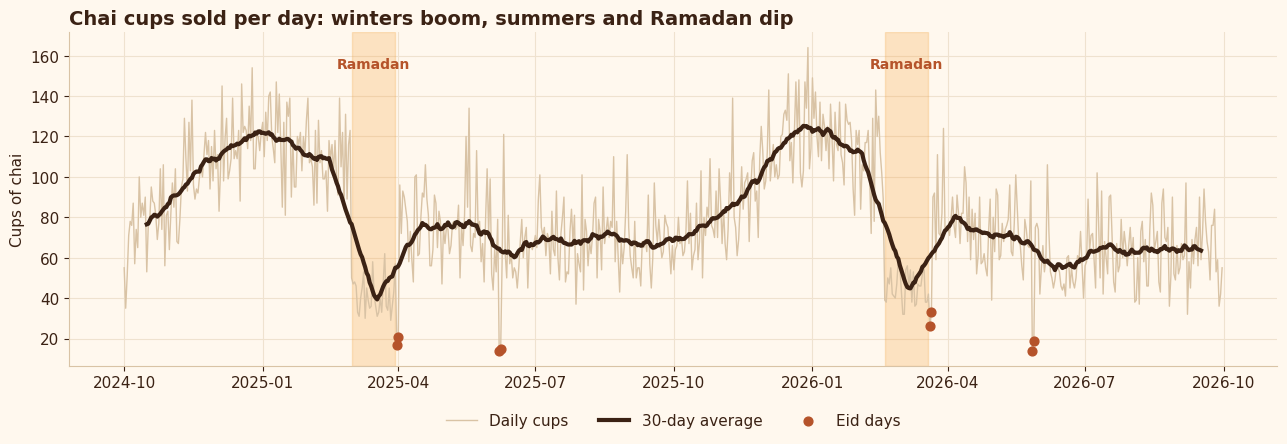

In [3]:
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.plot(df["date"], df["chai_cups_sold"], color=SAND, lw=1, label="Daily cups")
ax.plot(df["date"], df["chai_cups_sold"].rolling(30, center=True).mean(), color=BROWN, lw=3, label="30-day average")

# shade Ramadan blocks, mark Eid days
is_r = (df["special_day"] == "Ramadan")
blocks = (is_r != is_r.shift()).cumsum()[is_r]
for _, g in df[is_r].groupby(blocks):
    ax.axvspan(g["date"].min(), g["date"].max(), color=AMBER, alpha=.25)
    ax.text(g["date"].min() + (g["date"].max() - g["date"].min())/2, df["chai_cups_sold"].max()*0.97,
            "Ramadan", ha="center", va="top", fontsize=10, color=RUST, fontweight="bold")
eid = df[df["special_day"] == "Eid"]
ax.scatter(eid["date"], eid["chai_cups_sold"], color=RUST, s=40, zorder=5, label="Eid days")

ax.set_title("Chai cups sold per day: winters boom, summers and Ramadan dip")
ax.set_ylabel("Cups of chai"); ax.legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(.5, -.1))
plt.tight_layout(); plt.show()

## 5. Weather: the colder and wetter, the more tea

In [4]:
print("shape of df:", df.shape)
print("\nspecial_day value_counts:")
print(df["special_day"].value_counts(dropna=False))
print("\nordinary rows:", len(df[df["special_day"] == "Normal"]))


shape of df: (730, 17)

special_day value_counts:
special_day
NaN               658
Ramadan            60
Eid                 8
Public Holiday      4
Name: count, dtype: int64

ordinary rows: 0


ordinary rows: 658


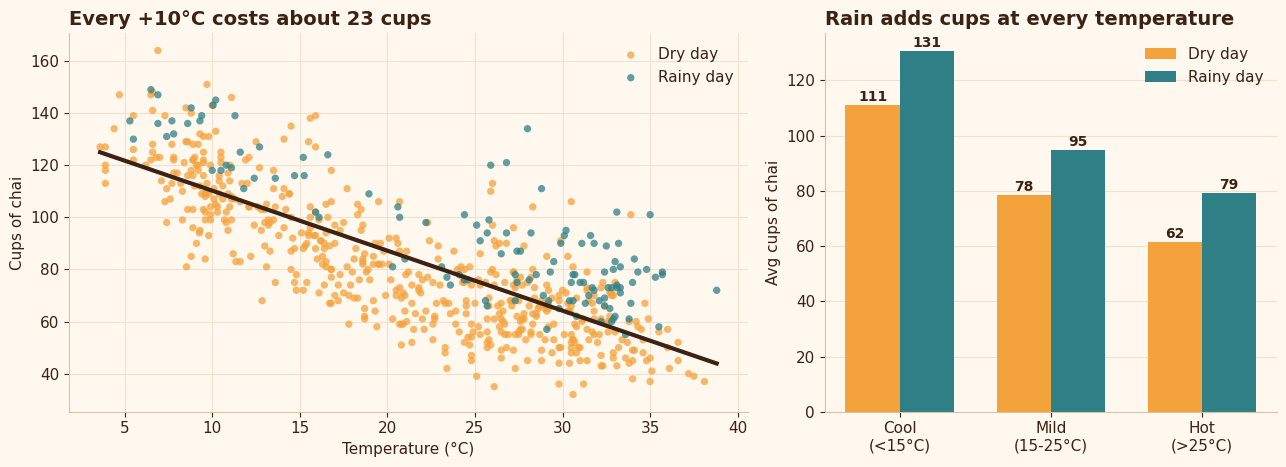

In [5]:
ordinary = df[df["special_day"].fillna("Normal") == "Normal"].dropna(subset=["temp_c", "chai_cups_sold"])
print(f"ordinary rows: {len(ordinary)}")

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

rainy = ordinary["rain_mm"] > 0
a.scatter(ordinary.loc[~rainy, "temp_c"], ordinary.loc[~rainy, "chai_cups_sold"], c=AMBER, s=28, alpha=.75, label="Dry day", edgecolor="none")
a.scatter(ordinary.loc[rainy, "temp_c"],  ordinary.loc[rainy, "chai_cups_sold"],  c=TEAL,  s=28, alpha=.75, label="Rainy day", edgecolor="none")
m, c0 = np.polyfit(ordinary["temp_c"], ordinary["chai_cups_sold"], 1)
xs = np.linspace(ordinary["temp_c"].min(), ordinary["temp_c"].max(), 50)
a.plot(xs, m*xs + c0, color=BROWN, lw=3)
a.set_title("Every +10°C costs about %d cups" % abs(round(m*10)))
a.set_xlabel("Temperature (°C)"); a.set_ylabel("Cups of chai"); a.legend(frameon=False)

band = pd.cut(ordinary["temp_c"], [-10, 15, 25, 50],
              labels=["Cool\n(<15°C)", "Mild\n(15-25°C)", "Hot\n(>25°C)"],
              include_lowest=True)
tab = (ordinary.assign(band=band, wet=np.where(rainy, "Rainy", "Dry"))
       .pivot_table(index="band", columns="wet", values="chai_cups_sold", aggfunc="mean", observed=True))
xs2 = np.arange(len(tab)); w = .36
b1 = b.bar(xs2 - w/2, tab["Dry"],   w, color=AMBER, label="Dry day")
b2 = b.bar(xs2 + w/2, tab["Rainy"], w, color=TEAL,  label="Rainy day")
for bars in (b1, b2):
    for r in bars:
        b.text(r.get_x() + r.get_width()/2, r.get_height() + 1.5,
               f"{r.get_height():.0f}", ha="center", fontweight="bold", fontsize=10)
b.set_xticks(xs2); b.set_xticklabels(tab.index); b.set_ylabel("Avg cups of chai"); b.grid(axis="x", visible=False)
b.set_title("Rain adds cups at every temperature"); b.legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. What boosts (or kills) sales?

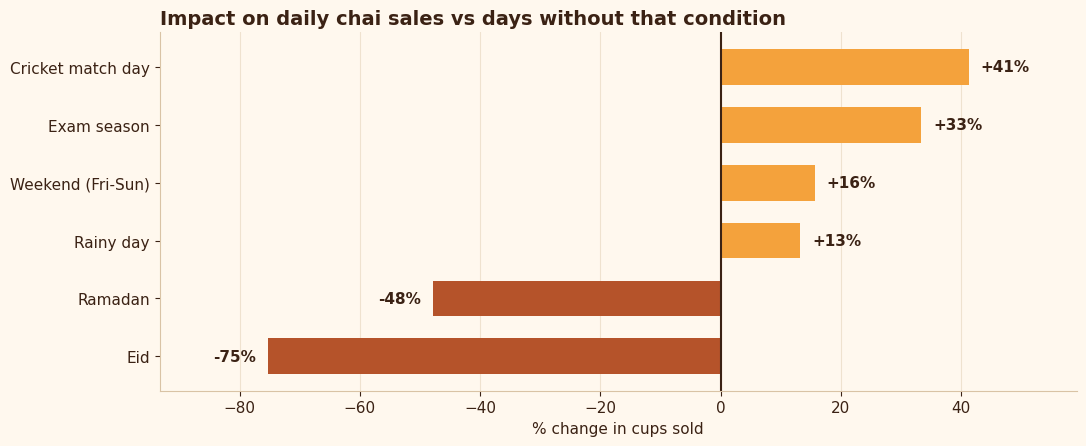

In [6]:
conds = {
    "Cricket match day": df["cricket_match_day"] == "Yes",
    "Rainy day":         df["rain_mm"] > 0,
    "Exam season":       df["exam_season"] == "Yes",
    "Weekend (Fri-Sun)": df["is_weekend"] == 1,
    "Ramadan":           df["special_day"] == "Ramadan",
    "Eid":               df["special_day"] == "Eid",
}
lift = {k: (df.loc[v, "chai_cups_sold"].mean() / df.loc[~v, "chai_cups_sold"].mean() - 1) * 100 for k, v in conds.items()}
s = pd.Series(lift).sort_values()

fig, ax = plt.subplots(figsize=(11, 4.6))
bars = ax.barh(s.index, s.values, color=[RUST if v < 0 else AMBER for v in s.values], height=.62)
for bar, v in zip(bars, s.values):
    ax.text(v + (2 if v >= 0 else -2), bar.get_y() + bar.get_height()/2, f"{v:+.0f}%",
            va="center", ha="left" if v >= 0 else "right", fontweight="bold", color=BROWN)
ax.axvline(0, color=BROWN, lw=1.5)
ax.set_xlim(s.min() - 18, s.max() + 18); ax.grid(axis="y", visible=False)
ax.set_title("Impact on daily chai sales vs days without that condition"); ax.set_xlabel("% change in cups sold")
plt.tight_layout(); plt.show()

## 7. Which day and month is busiest?

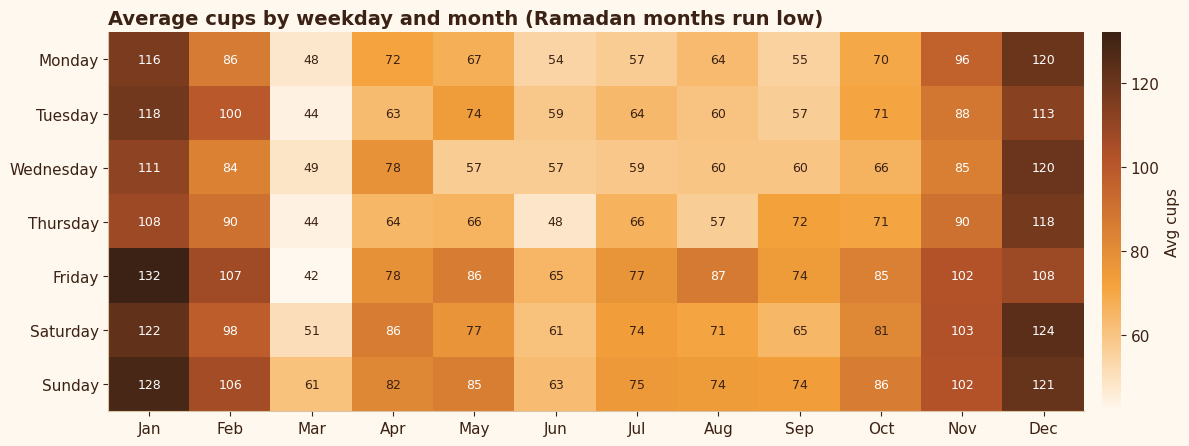

In [7]:
order_d = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
order_m = ["January","February","March","April","May","June","July","August","September","October","November","December"]
pt = df.pivot_table(index="day_of_week", columns="month", values="chai_cups_sold", aggfunc="mean").reindex(index=order_d, columns=order_m)

cmap = LinearSegmentedColormap.from_list("chai", [CREAM, AMBER, RUST, BROWN])
fig, ax = plt.subplots(figsize=(13, 4.6))
im = ax.imshow(pt.values, cmap=cmap, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3] for m in order_m])
ax.set_yticks(range(7));  ax.set_yticklabels(order_d); ax.grid(False)
for i in range(7):
    for j in range(12):
        v = pt.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > np.nanpercentile(pt.values, 60) else BROWN)
ax.set_title("Average cups by weekday and month (Ramadan months run low)")
cb = plt.colorbar(im, ax=ax, pad=.015); cb.outline.set_visible(False); cb.set_label("Avg cups")
plt.tight_layout(); plt.show()

## 8. Can a model predict tomorrow's chai?

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

X = pd.DataFrame({
    "temp_c": df["temp_c"], "rain_mm": df["rain_mm"], "is_weekend": df["is_weekend"],
    "cricket_day": (df["cricket_match_day"] == "Yes").astype(int), "exam_season": (df["exam_season"] == "Yes").astype(int),
    "staff_on_duty": df["staff_on_duty"], "chai_price_pkr": df["chai_price_pkr"],
    "is_ramadan": (df["special_day"] == "Ramadan").astype(int), "is_eid": (df["special_day"] == "Eid").astype(int),
    "is_holiday": (df["special_day"] == "Public Holiday").astype(int),
})
y = df["chai_cups_sold"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=42)

lr = LinearRegression().fit(Xtr, ytr)
rf = RandomForestRegressor(n_estimators=300, random_state=42).fit(Xtr, ytr)
res = {name: (r2_score(yte, m.predict(Xte)), mean_absolute_error(yte, m.predict(Xte)))
       for name, m in [("Linear Regression", lr), ("Random Forest", rf)]}
for name, (r2, mae) in res.items():
    print(f"{name:18s}  R2 = {r2:.2f}   average error = {mae:.1f} cups")

Linear Regression   R2 = 0.88   average error = 8.4 cups
Random Forest       R2 = 0.89   average error = 7.4 cups


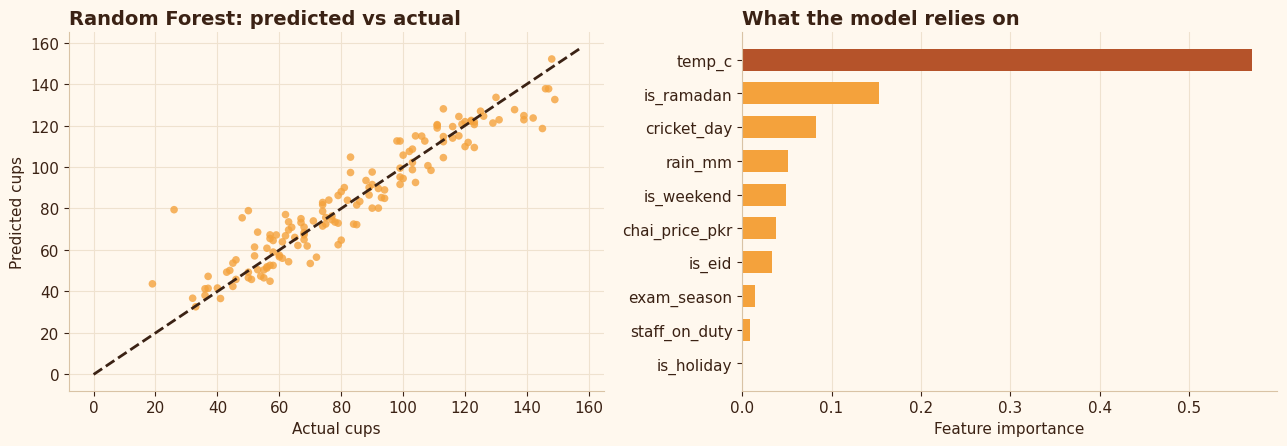

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6))
pred = rf.predict(Xte)
a.scatter(yte, pred, c=AMBER, s=30, alpha=.8, edgecolor="none")
lim = [0, max(yte.max(), pred.max()) + 5]; a.plot(lim, lim, color=BROWN, lw=2, ls="--")
a.set_title("Random Forest: predicted vs actual"); a.set_xlabel("Actual cups"); a.set_ylabel("Predicted cups")
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
b.barh(imp.index, imp.values, color=[RUST if v == imp.max() else AMBER for v in imp.values], height=.65)
b.set_title("What the model relies on"); b.set_xlabel("Feature importance"); b.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 9. Key takeaways

<div style="display:flex;gap:14px;flex-wrap:wrap"><div style="flex:1;min-width:230px;background:linear-gradient(160deg,#fff8ee,#f7e6cc);border:1px solid #e8d5b8;border-radius:14px;padding:18px;font-family:Arial,sans-serif"><div style="font-size:30px">&#127783;</div><div style="font-weight:bold;font-size:16px;color:#3b2214;margin:6px 0">Weather drives demand</div><div style="font-size:13.5px;color:#6b4a35;line-height:1.45">Every +10&deg;C costs about 23 cups, and rainy days add about 13% overall.</div></div><div style="flex:1;min-width:230px;background:linear-gradient(160deg,#fff8ee,#f7e6cc);border:1px solid #e8d5b8;border-radius:14px;padding:18px;font-family:Arial,sans-serif"><div style="font-size:30px">&#127951;</div><div style="font-weight:bold;font-size:16px;color:#3b2214;margin:6px 0">Cricket nights are gold</div><div style="font-size:13.5px;color:#6b4a35;line-height:1.45">Match days lift chai sales by +41%, more than any weekend.</div></div><div style="flex:1;min-width:230px;background:linear-gradient(160deg,#fff8ee,#f7e6cc);border:1px solid #e8d5b8;border-radius:14px;padding:18px;font-family:Arial,sans-serif"><div style="font-size:30px">&#127769;</div><div style="font-weight:bold;font-size:16px;color:#3b2214;margin:6px 0">Ramadan flips the day</div><div style="font-size:13.5px;color:#6b4a35;line-height:1.45">Sales fall by 48% (people fast) and Eid is the quietest of all.</div></div><div style="flex:1;min-width:230px;background:linear-gradient(160deg,#fff8ee,#f7e6cc);border:1px solid #e8d5b8;border-radius:14px;padding:18px;font-family:Arial,sans-serif"><div style="font-size:30px">&#129302;</div><div style="font-weight:bold;font-size:16px;color:#3b2214;margin:6px 0">Simple models work</div><div style="font-size:13.5px;color:#6b4a35;line-height:1.45">A Random Forest explains 89% of daily variation with just 10 features.</div></div></div><div style="margin-top:18px;padding:16px 20px;background:#3b2214;color:#fff3e0;border-radius:12px;font-family:Arial,sans-serif;font-size:14px;line-height:1.6"><b style="color:#f4a23c">Try next:</b> predict <code style="color:#f4a23c;background:transparent">daily_revenue_pkr</code> &middot; build a "high sales day" classifier &middot; test whether raising the chai price really hurts demand &middot; forecast the next 30 days with a time-series model.<br><span style="color:#d9c3a5">If you enjoyed this notebook, an upvote on the notebook and the dataset means a lot! &#9749;</span></div>